# Project CheckIn - 2
Author: Jaswanthi Mandalapu (019148883)

Date: 20 Oct 2026

In [1]:
!nvidia-smi

Wed Oct 21 01:05:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# transformers: Load and run the reasoning language model
# accelerate: Support GPU execution and model placement
# datasets: Load GSM8K and, later, MATH-500
# pandas: Store and analyze experimental results
# matplotlib: Generate plots
# scikit-learn: Useful for later evaluation and Adaptive DEER

!pip -q install -U transformers accelerate datasets \
    safetensors sentencepiece pandas matplotlib scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 63.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 53.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 11.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
c

In [3]:
import os
import re
import time
import random

import numpy as np
import pandas as pd
import torch

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM

# -------------------------------------------------------
# Experiment configuration
# -------------------------------------------------------

MODEL_NAME = "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B"

DATASET_NAME = "openai/gsm8k"
DATASET_CONFIG = "main"

# Start with 20 questions to test the pipeline.
NUM_SAMPLES = 20

# Allow more reasoning tokens than our initial 1024-token run.
MAX_NEW_TOKENS = 2048

# Set random seeds for reproducibility.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Confirm GPU availability.
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [4]:
# -------------------------------------------------------
# Load tokenizer
# -------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# -------------------------------------------------------
# Load pretrained reasoning model
# -------------------------------------------------------

# float16 reduces GPU memory usage.
# device_map="auto" automatically places the model
# on the available hardware.

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

# Enable evaluation mode.
# We are performing inference, not training.
model.eval()

print("Model loaded successfully!")
print("Model device:", model.device)

config.json:   0%|          | 0.00/679 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.55GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

Model loaded successfully!
Model device: cuda:0


In [5]:
# -------------------------------------------------------
# Test DeepSeek-R1-Distill-Qwen-1.5B
# -------------------------------------------------------

# Step 1: Define a simple mathematical reasoning question.

question = """
A shop sells 5 notebooks for $20.
How much do 8 notebooks cost?
"""

# Step 2: Format the question using the model's chat template.

messages = [
    {
        "role": "user",
        "content": question
    }
]

prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

# Step 3: Convert the prompt into input tokens.

inputs = tokenizer(
    prompt,
    return_tensors="pt"
).to(model.device)

# Step 4: Generate the reasoning response.

print("Generating response...\n")

with torch.inference_mode():

    outputs = model.generate(
        **inputs,

        # Maximum number of generated tokens
        max_new_tokens=1024,

        # Use greedy decoding
        do_sample=False,

        # Padding configuration
        pad_token_id=tokenizer.eos_token_id
    )

# Step 5: Extract only the generated tokens.
# The output contains both input and generated tokens.

input_length = inputs["input_ids"].shape[1]

generated_ids = outputs[0][input_length:]

# Step 6: Decode the generated tokens into readable text.

response = tokenizer.decode(
    generated_ids,
    skip_special_tokens=False
)

# Step 7: Display the results.

print("=" * 60)
print("QUESTION:")
print(question)

print("=" * 60)
print("MODEL RESPONSE:")
print(response)

print("=" * 60)
print("GENERATED TOKENS:", len(generated_ids))

print("EXPECTED ANSWER: 32")

Generating response...

QUESTION:

A shop sells 5 notebooks for $20.
How much do 8 notebooks cost?

MODEL RESPONSE:
First, determine the cost per notebook by dividing the total cost by the number of notebooks. 

Then, multiply the cost per notebook by the number of notebooks you want to find the total cost for 8 notebooks.
</think>

To determine the cost of 8 notebooks, follow these steps:

1. **Find the cost per notebook:**
   
   The shop sells 5 notebooks for \$20. 
   
   \[
   \text{Cost per notebook} = \frac{\$20}{5} = \$4
   \]

2. **Calculate the cost for 8 notebooks:**
   
   \[
   \text{Total cost for 8 notebooks} = 8 \times \$4 = \$32
   \]

**Final Answer:**
\[
\boxed{\$32}
\]<｜end▁of▁sentence｜>
GENERATED TOKENS: 170
EXPECTED ANSWER: 32


In [6]:
# GSM8K is a mathematical reasoning benchmark.
# Each example contains:
#   1. question: Math word problem
#   2. answer: Worked solution and final numerical answer
#
# The ground-truth final answer appears after "####".

gsm8k = load_dataset(
    DATASET_NAME,
    DATASET_CONFIG
)

print(gsm8k)

# Display one example.
print("\nExample question:")
print(gsm8k["test"][0]["question"])

print("\nGround-truth answer:")
print(gsm8k["test"][0]["answer"])

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['question', 'answer'],
        num_rows: 7473
    })
    test: Dataset({
        features: ['question', 'answer'],
        num_rows: 1319
    })
})

Example question:
Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?

Ground-truth answer:
Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 duck eggs a day.
She makes 9 * 2 = $<<9*2=18>>18 every day at the farmer’s market.
#### 18


In [7]:
# Use the first 20 GSM8K test questions.
#
# This is a preliminary baseline experiment.
# We will use a larger evaluation set later.

test_data = gsm8k["test"].select(
    range(NUM_SAMPLES)
)

print("Number of evaluation questions:", len(test_data))

Number of evaluation questions: 20


In [8]:
def generate_full_cot(question, max_new_tokens=MAX_NEW_TOKENS):
    """
    Generate a full Chain-of-Thought response.

    Parameters
    ----------
    question : str
        Mathematical reasoning question.

    max_new_tokens : int
        Maximum number of tokens the model can generate.

    Returns
    -------
    dict
        response: Generated model response.
        generated_tokens: Number of generated tokens.
        latency: Total generation time in seconds.
        reached_token_limit: Whether generation used the full budget.
        finished_with_eos: Whether generation ended with EOS.
    """

    # ---------------------------------------------------
    # Step 1: Format the question using the chat template
    # ---------------------------------------------------

    messages = [
        {
            "role": "user",
            "content": question
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # ---------------------------------------------------
    # Step 2: Tokenize input
    # ---------------------------------------------------

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    input_length = inputs["input_ids"].shape[1]

    # ---------------------------------------------------
    # Step 3: Run model inference
    # ---------------------------------------------------

    # Synchronize GPU before timing.
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.inference_mode():

        outputs = model.generate(
            **inputs,

            # Maximum number of generated tokens
            max_new_tokens=max_new_tokens,

            # Greedy decoding for a reproducible baseline
            do_sample=False,

            # EOS/padding configuration
            pad_token_id=tokenizer.eos_token_id
        )

    # Synchronize GPU to measure completed inference.
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed_time = time.perf_counter() - start_time

    # ---------------------------------------------------
    # Step 4: Extract newly generated tokens
    # ---------------------------------------------------

    # outputs contains both input and generated tokens.
    # Remove input tokens to obtain the model response.

    generated_ids = outputs[0][input_length:]

    # Keep special tokens so we can inspect the response.
    response = tokenizer.decode(
        generated_ids,
        skip_special_tokens=False
    )

    generated_tokens = len(generated_ids)

    # ---------------------------------------------------
    # Step 5: Check generation completion
    # ---------------------------------------------------

    # Reaching the token limit does not always mean
    # the answer is incomplete.
    reached_token_limit = (
        generated_tokens >= max_new_tokens
    )

    eos_ids = model.generation_config.eos_token_id

    if eos_ids is None:
        eos_ids = tokenizer.eos_token_id

    if isinstance(eos_ids, int):
        eos_ids = [eos_ids]

    finished_with_eos = (
        generated_tokens > 0
        and generated_ids[-1].item() in eos_ids
    )

    # ---------------------------------------------------
    # Step 6: Return results
    # ---------------------------------------------------

    return {
        "response": response,
        "generated_tokens": generated_tokens,
        "latency": elapsed_time,
        "reached_token_limit": reached_token_limit,
        "finished_with_eos": finished_with_eos
    }

In [9]:
# Test the inference pipeline before running the dataset.

question = """
A shop sells 5 notebooks for $20.
How much do 8 notebooks cost?
"""

output = generate_full_cot(
    question,
    max_new_tokens=512
)

print("MODEL RESPONSE:")
print(output["response"])

print("\nGenerated tokens:", output["generated_tokens"])
print("Latency:", round(output["latency"], 2), "seconds")
print("Finished with EOS:", output["finished_with_eos"])

MODEL RESPONSE:
First, determine the cost per notebook by dividing the total cost by the number of notebooks. 

Then, multiply the cost per notebook by the number of notebooks you want to find the total cost for 8 notebooks.
</think>

To determine the cost of 8 notebooks, follow these steps:

1. **Find the cost per notebook:**
   
   The shop sells 5 notebooks for \$20. 
   
   \[
   \text{Cost per notebook} = \frac{\$20}{5} = \$4
   \]

2. **Calculate the cost for 8 notebooks:**
   
   \[
   \text{Total cost for 8 notebooks} = 8 \times \$4 = \$32
   \]

**Final Answer:**
\[
\boxed{\$32}
\]<｜end▁of▁sentence｜>

Generated tokens: 170
Latency: 6.08 seconds
Finished with EOS: True


In [10]:
def extract_ground_truth(answer):
    """
    Extract the final numerical answer from GSM8K.

    Example
    -------
    Input:
        "Some reasoning #### 57,500"

    Output:
        "57500"
    """

    # GSM8K places its final answer after "####".
    final_answer = answer.split("####")[-1].strip()

    # Remove commas and currency symbols.
    final_answer = final_answer.replace(",", "")
    final_answer = final_answer.replace("$", "")

    return final_answer

In [11]:
def extract_prediction(response):
    """
    Extract the final numerical prediction from a model response.

    Handles common formats such as:
        \\boxed{180}
        \\boxed{65,000}
        \\boxed{57,\\!500}
        \\boxed{\\$221}
        Final Answer: 42

    Returns None if no numerical answer is found.
    """

    # ---------------------------------------------------
    # Step 1: Prefer the final answer after </think>
    # ---------------------------------------------------

    if "</think>" in response:
        text = response.split("</think>")[-1]
    else:
        text = response

    # ---------------------------------------------------
    # Step 2: Remove LaTeX spacing commands
    # ---------------------------------------------------

    # Examples:
    #   57,\\!500 -> 57,500
    #   57,\\,500 -> 57,500

    text = re.sub(
        r"\\[,;!:\s]",
        "",
        text
    )

    # ---------------------------------------------------
    # Step 3: Prefer a boxed answer
    # ---------------------------------------------------

    boxed = re.findall(
        r"\\boxed\s*\{([^{}]*)\}",
        text
    )

    if boxed:
        text = boxed[-1]

    # ---------------------------------------------------
    # Step 4: Remove formatting characters
    # ---------------------------------------------------

    text = text.replace(r"\$", "$")
    text = text.replace("$", "")
    text = text.replace(",", "")

    # ---------------------------------------------------
    # Step 5: Extract numerical values
    # ---------------------------------------------------

    numbers = re.findall(
        r"-?\d+(?:\.\d+)?",
        text
    )

    if not numbers:
        return None

    # Take the last number in the selected text.
    return numbers[-1]

In [12]:
def normalize_number(value):
    """
    Convert numerical answer strings into floats.

    Examples
    --------
    "57,500" -> 57500.0
    "$125"   -> 125.0
    "18"     -> 18.0
    """

    if value is None:
        return None

    try:
        value = str(value)

        value = value.replace("$", "")
        value = value.replace(",", "")
        value = value.strip()

        return float(value)

    except (ValueError, TypeError):
        return None


def is_correct_prediction(prediction, ground_truth):
    """
    Compare the model prediction with the ground truth.
    """

    pred = normalize_number(prediction)
    truth = normalize_number(ground_truth)

    if pred is None or truth is None:
        return False

    return abs(pred - truth) < 1e-6

In [13]:
# Check that our parser handles common answer formats.

test_responses = [
    r"\boxed{180}",
    r"\boxed{65,000}",
    r"\boxed{57,\!500}",
    r"\boxed{\$221}",
    "The final answer is 42.",
    "Therefore, the answer is 18."
]

for response in test_responses:

    prediction = extract_prediction(response)

    print(
        f"Input: {response:35s} "
        f"Prediction: {prediction}"
    )

Input: \boxed{180}                         Prediction: 180
Input: \boxed{65,000}                      Prediction: 65000
Input: \boxed{57,\!500}                    Prediction: 57500
Input: \boxed{\$221}                       Prediction: 221
Input: The final answer is 42.             Prediction: 42
Input: Therefore, the answer is 18.        Prediction: 18


In [14]:
# -------------------------------------------------------
# Full Chain-of-Thought baseline evaluation
# -------------------------------------------------------

results = []

for i, example in enumerate(test_data):

    # ---------------------------------------------------
    # Step 1: Read question and ground truth
    # ---------------------------------------------------

    question = example["question"]

    ground_truth = extract_ground_truth(
        example["answer"]
    )

    # ---------------------------------------------------
    # Step 2: Generate complete reasoning response
    # ---------------------------------------------------

    output = generate_full_cot(
        question,
        max_new_tokens=MAX_NEW_TOKENS
    )

    # ---------------------------------------------------
    # Step 3: Extract the model's final answer
    # ---------------------------------------------------

    prediction = extract_prediction(
        output["response"]
    )

    # ---------------------------------------------------
    # Step 4: Evaluate correctness
    # ---------------------------------------------------

    correct = is_correct_prediction(
        prediction,
        ground_truth
    )

    # ---------------------------------------------------
    # Step 5: Store experiment results
    # ---------------------------------------------------

    results.append({
        "question_id": i,
        "question": question,
        "ground_truth": ground_truth,
        "prediction": prediction,
        "correct": correct,
        "generated_tokens": output["generated_tokens"],
        "latency": output["latency"],
        "reached_token_limit": output["reached_token_limit"],
        "finished_with_eos": output["finished_with_eos"],
        "response": output["response"]
    })

    # ---------------------------------------------------
    # Step 6: Display progress
    # ---------------------------------------------------

    print(
        f"Question {i+1}/{len(test_data)} | "
        f"Correct: {correct} | "
        f"Tokens: {output['generated_tokens']} | "
        f"EOS: {output['finished_with_eos']}"
    )

# Convert results into a Pandas DataFrame.
df = pd.DataFrame(results)

print("\nEvaluation completed!")

Question 1/20 | Correct: True | Tokens: 461 | EOS: True
Question 2/20 | Correct: True | Tokens: 323 | EOS: True
Question 3/20 | Correct: False | Tokens: 463 | EOS: True
Question 4/20 | Correct: False | Tokens: 204 | EOS: True
Question 5/20 | Correct: True | Tokens: 426 | EOS: True
Question 6/20 | Correct: True | Tokens: 341 | EOS: True
Question 7/20 | Correct: True | Tokens: 423 | EOS: True
Question 8/20 | Correct: False | Tokens: 674 | EOS: True
Question 9/20 | Correct: False | Tokens: 2048 | EOS: False
Question 10/20 | Correct: True | Tokens: 491 | EOS: True
Question 11/20 | Correct: True | Tokens: 392 | EOS: True
Question 12/20 | Correct: True | Tokens: 441 | EOS: True
Question 13/20 | Correct: False | Tokens: 492 | EOS: True
Question 14/20 | Correct: True | Tokens: 1214 | EOS: True
Question 15/20 | Correct: True | Tokens: 506 | EOS: True
Question 16/20 | Correct: False | Tokens: 484 | EOS: True
Question 17/20 | Correct: True | Tokens: 349 | EOS: True
Question 18/20 | Correct: True 

In [15]:
# -------------------------------------------------------
# Calculate Full CoT baseline performance
# -------------------------------------------------------

accuracy = df["correct"].mean() * 100

avg_tokens = df["generated_tokens"].mean()

total_tokens = df["generated_tokens"].sum()

avg_latency = df["latency"].mean()

token_limit_hits = df["reached_token_limit"].sum()

eos_completed = df["finished_with_eos"].sum()

print("=" * 55)
print("FULL CHAIN-OF-THOUGHT BASELINE RESULTS")
print("=" * 55)

print(f"Model: {MODEL_NAME}")
print(f"Dataset: GSM8K")
print(f"Questions evaluated: {len(df)}")

print("-" * 55)

print(f"Accuracy: {accuracy:.2f}%")
print(f"Correct answers: {df['correct'].sum()}/{len(df)}")

print(f"Average generated tokens: {avg_tokens:.2f}")
print(f"Total generated tokens: {total_tokens}")

print(f"Average latency: {avg_latency:.2f} seconds")

print(f"Token limit hits: {token_limit_hits}")
print(f"EOS-completed responses: {eos_completed}")

print("=" * 55)

FULL CHAIN-OF-THOUGHT BASELINE RESULTS
Model: deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B
Dataset: GSM8K
Questions evaluated: 20
-------------------------------------------------------
Accuracy: 65.00%
Correct answers: 13/20
Average generated tokens: 634.50
Total generated tokens: 12690
Average latency: 22.52 seconds
Token limit hits: 2
EOS-completed responses: 18


In [16]:
# Display a summary of each question.
# Exclude full responses to keep the table readable.

display(
    df[
        [
            "question_id",
            "ground_truth",
            "prediction",
            "correct",
            "generated_tokens",
            "latency",
            "reached_token_limit",
            "finished_with_eos"
        ]
    ]
)

,question_id,ground_truth,prediction,correct,generated_tokens,latency,reached_token_limit,finished_with_eos
0,0,18,18,True,461,16.364111,False,True
1,1,3,3,True,323,11.497209,False,True
2,2,70000,65000,False,463,16.444175,False,True
3,3,540,180,False,204,7.224120,False,True
4,4,20,20,True,426,14.943236,False,True
5,5,64,64,True,341,12.137340,False,True
6,6,260,260,True,423,15.073357,False,True
7,7,160,120,False,674,23.842514,False,True
8,8,45,180,False,2048,72.761343,True,False
9,9,460,460,True,491,17.528647,False,True


In [17]:
# Review incorrect predictions to identify:
#   1. Model reasoning errors
#   2. Answer extraction errors
#   3. Incomplete responses

for i, row in df.iterrows():

    if not row["correct"]:

        print("=" * 70)

        print("Question ID:", row["question_id"])
        print("Question:", row["question"])

        print("\nGround truth:", row["ground_truth"])
        print("Prediction:", row["prediction"])

        print("Generated tokens:", row["generated_tokens"])
        print("Reached token limit:", row["reached_token_limit"])
        print("Finished with EOS:", row["finished_with_eos"])

        print("\nResponse ending:")
        print(row["response"][-1200:])

Question ID: 2
Question: Josh decides to try flipping a house.  He buys a house for $80,000 and then puts in $50,000 in repairs.  This increased the value of the house by 150%.  How much profit did he make?

Ground truth: 70000
Prediction: 65000
Generated tokens: 463
Reached token limit: False
Finished with EOS: True

Response ending:
 Josh spent $80,000 on the house and an additional $50,000 in repairs, which adds up to $130,000.

Next, I'll determine the increased value of the house. The problem states that this increase is 150%, which means the value went up by 1.5 times the original cost. Multiplying $130,000 by 1.5 gives a new value of $195,000.

Finally, to find the profit, I'll subtract the total cost from the new value. $195,000 minus $130,000 equals a profit of $65,000.
</think>

To determine Josh's profit from buying and flipping his house, let's break down the costs and the resulting value of the house.

1. **Initial Purchase:**
   - **Cost of the house:** \$80,000

2. **Rep

In [18]:
# Mark responses that completed normally.
df["completed"] = df["finished_with_eos"]

# A valid Full CoT prediction must be completed.
df["valid_correct"] = (
    df["correct"] & df["completed"]
)

print("Completed responses:", df["completed"].sum())
print("Incomplete responses:", (~df["completed"]).sum())

print(
    "Completed-answer accuracy:",
    round(df["valid_correct"].mean() * 100, 2),
    "%"
)

print(
    "Accuracy among completed responses:",
    round(
        df.loc[df["completed"], "correct"].mean() * 100,
        2
    ),
    "%"
)

Completed responses: 18
Incomplete responses: 2
Completed-answer accuracy: 65.0 %
Accuracy among completed responses: 72.22 %


In [20]:
# -------------------------------------------------------
# Save Full CoT baseline results to Google Drive
# -------------------------------------------------------

from google.colab import drive
from pathlib import Path
import os
import json
import pandas as pd

# Connect Google Drive to Colab.
drive.mount("/content/drive")

# Create a separate folder for Full CoT results.
BASELINE_DIR = Path(
    "/content/drive/MyDrive/DEER_Project/Full_CoT_Baseline"
)

BASELINE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Baseline directory:", BASELINE_DIR)

Mounted at /content/drive
Baseline directory: /content/drive/MyDrive/DEER_Project/Full_CoT_Baseline


In [21]:
# -------------------------------------------------------
# Save complete baseline results
# -------------------------------------------------------

# CSV file: Easy to open in Excel or Pandas.
csv_path = BASELINE_DIR / "full_cot_results.csv"

df.to_csv(
    csv_path,
    index=False
)

# JSON file: Preserves full text and structured records.
json_path = BASELINE_DIR / "full_cot_results.json"

df.to_json(
    json_path,
    orient="records",
    indent=4,
    force_ascii=False
)

print("Saved CSV:", csv_path)
print("Saved JSON:", json_path)
print("Number of questions saved:", len(df))

Saved CSV: /content/drive/MyDrive/DEER_Project/Full_CoT_Baseline/full_cot_results.csv
Saved JSON: /content/drive/MyDrive/DEER_Project/Full_CoT_Baseline/full_cot_results.json
Number of questions saved: 20


In [22]:
# -------------------------------------------------------
# Calculate and save baseline summary metrics
# -------------------------------------------------------

baseline_metrics = {
    "model": MODEL_NAME,
    "dataset": "GSM8K",
    "method": "Full Chain-of-Thought",

    "num_questions": int(len(df)),
    "max_new_tokens": int(MAX_NEW_TOKENS),

    # Accuracy
    "correct_answers": int(df["valid_correct"].sum()),
    "accuracy": float(df["valid_correct"].mean()),
    "accuracy_percent": float(
        df["valid_correct"].mean() * 100
    ),

    # Token usage
    "average_generated_tokens": float(
        df["generated_tokens"].mean()
    ),
    "total_generated_tokens": int(
        df["generated_tokens"].sum()
    ),

    # Latency
    "average_latency_seconds": float(
        df["latency"].mean()
    ),
    "total_latency_seconds": float(
        df["latency"].sum()
    ),

    # Generation completion
    "completed_responses": int(
        df["completed"].sum()
    ),
    "incomplete_responses": int(
        (~df["completed"]).sum()
    ),

    "token_limit_hits": int(
        df["reached_token_limit"].sum()
    )
}

metrics_path = BASELINE_DIR / "baseline_metrics.json"

with open(metrics_path, "w") as f:
    json.dump(
        baseline_metrics,
        f,
        indent=4
    )

print("Saved:", metrics_path)

print("\nBASELINE SUMMARY")
print("-" * 45)

print(
    f"Accuracy: {baseline_metrics['accuracy_percent']:.2f}%"
)

print(
    f"Average tokens: "
    f"{baseline_metrics['average_generated_tokens']:.2f}"
)

print(
    f"Average latency: "
    f"{baseline_metrics['average_latency_seconds']:.2f} seconds"
)

Saved: /content/drive/MyDrive/DEER_Project/Full_CoT_Baseline/baseline_metrics.json

BASELINE SUMMARY
---------------------------------------------
Accuracy: 65.00%
Average tokens: 634.50
Average latency: 22.52 seconds


In [23]:
# -------------------------------------------------------
# Save GSM8K evaluation dataset
# -------------------------------------------------------

evaluation_questions = []

for i, example in enumerate(test_data):

    evaluation_questions.append({
        "question_id": i,
        "question": example["question"],
        "ground_truth": extract_ground_truth(
            example["answer"]
        )
    })

dataset_path = BASELINE_DIR / "gsm8k_evaluation_questions.json"

with open(dataset_path, "w") as f:
    json.dump(
        evaluation_questions,
        f,
        indent=4
    )

print("Saved:", dataset_path)
print("Questions saved:", len(evaluation_questions))

Saved: /content/drive/MyDrive/DEER_Project/Full_CoT_Baseline/gsm8k_evaluation_questions.json
Questions saved: 20


In [24]:
# -------------------------------------------------------
# Save Full CoT experiment configuration
# -------------------------------------------------------

experiment_config = {
    "experiment_name": "Full_CoT_GSM8K_Baseline",
    "model_name": MODEL_NAME,

    "dataset": "openai/gsm8k",
    "dataset_config": "main",
    "dataset_split": "test",

    "num_samples": NUM_SAMPLES,
    "sample_selection": "First 20 questions",

    "max_new_tokens": MAX_NEW_TOKENS,

    "decoding": {
        "do_sample": False,
        "method": "Greedy decoding"
    },

    "random_seed": SEED,

    "inference": {
        "torch_dtype": "float16",
        "device_map": "auto"
    },

    "prompt_format": "Tokenizer chat template, user-only message",

    "evaluation": {
        "answer_extraction": "Numeric extraction with LaTeX cleanup",
        "incomplete_responses_counted_as_incorrect": True
    }
}

config_path = BASELINE_DIR / "experiment_config.json"

with open(config_path, "w") as f:
    json.dump(
        experiment_config,
        f,
        indent=4
    )

print("Saved:", config_path)

Saved: /content/drive/MyDrive/DEER_Project/Full_CoT_Baseline/experiment_config.json


In [25]:
# -------------------------------------------------------
# Verify saved baseline results
# -------------------------------------------------------

# Load CSV back from Google Drive.
saved_df = pd.read_csv(
    BASELINE_DIR / "full_cot_results.csv"
)

# Load saved summary metrics.
with open(BASELINE_DIR / "baseline_metrics.json") as f:
    saved_metrics = json.load(f)

# Load evaluation questions.
with open(BASELINE_DIR / "gsm8k_evaluation_questions.json") as f:
    saved_questions = json.load(f)

# Verify number of questions.
assert len(saved_df) == len(df)
assert len(saved_questions) == len(df)

# Verify token counts.
assert (
    saved_df["generated_tokens"].sum()
    == df["generated_tokens"].sum()
)

# Verify full reasoning responses are present.
assert saved_df["response"].notna().all()

print("All baseline files verified successfully!")

print("\nSaved files:")

for file in sorted(BASELINE_DIR.iterdir()):
    print(
        f"{file.name:40s} "
        f"{file.stat().st_size / 1024:.2f} KB"
    )

All baseline files verified successfully!

Saved files:
baseline_metrics.json                    0.51 KB
experiment_config.json                   0.71 KB
full_cot_results.csv                     47.49 KB
full_cot_results.json                    54.73 KB
gsm8k_evaluation_questions.json          6.56 KB


## DEER Implementation

In [26]:
# -------------------------------------------------------
# Step 1.1: Download the official DEER code
# -------------------------------------------------------

from pathlib import Path
import subprocess

DEER_DIR = Path("/content/DEER")

# Clone only if the repository is not already present.
if not (DEER_DIR / ".git").exists():

    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/iie-ycx/DEER.git",
            str(DEER_DIR)
        ],
        check=True
    )

print("DEER repository:", DEER_DIR)
print("Repository exists:", DEER_DIR.exists())

DEER repository: /content/DEER
Repository exists: True


In [27]:
# -------------------------------------------------------
# Step 1.2: Verify DEER implementation files
# -------------------------------------------------------

files_to_check = [
    "README.md",
    "vanilla_deer.py",
    "requirements.txt"
]

for filename in files_to_check:

    path = DEER_DIR / filename

    print(
        filename,
        "FOUND" if path.exists() else "MISSING"
    )

# Show the files in the repository.
print("\nRepository files:")

for path in sorted(DEER_DIR.iterdir()):
    print(path.name)

README.md FOUND
vanilla_deer.py FOUND
requirements.txt FOUND

Repository files:
.git
LICENSE
README.md
bashes
check.py
data
images
prompts
requirements.txt
utils
vanilla_deer.py
vllm-deer-qwen3.py
vllm-deer.py


In [28]:
# -------------------------------------------------------
# Step 1.3: Inspect the implementation
# -------------------------------------------------------

script_path = DEER_DIR / "vanilla_deer.py"

# Read the original Python source.
source = script_path.read_text(encoding="utf-8")

print("Source loaded successfully!")
print("Source length:", len(source), "characters")

# Check the key DEER components.
components = {
    "Confidence calculation": "calcu_max_probs_w_kv",
    "KV cache": "DynamicCache",
    "Confidence threshold": "args.threshold",
    "Reasoning generation": "model.generate",
    "Trial-answer prompt": "answer_prompt_ids"
}

for name, keyword in components.items():

    print(
        f"{name:25s}:",
        "FOUND" if keyword in source else "NOT FOUND"
    )

Source loaded successfully!
Source length: 9272 characters
Confidence calculation   : FOUND
KV cache                 : FOUND
Confidence threshold     : FOUND
Reasoning generation     : FOUND
Trial-answer prompt      : FOUND


In [29]:
# -------------------------------------------------------
# Step 2.1: Load the exact GSM8K baseline questions
# -------------------------------------------------------

import json
from pathlib import Path

BASELINE_DIR = Path(
    "/content/drive/MyDrive/DEER_Project/Full_CoT_Baseline"
)

questions_path = BASELINE_DIR / "gsm8k_evaluation_questions.json"

# Load the questions saved during the baseline experiment.
with open(questions_path, "r") as f:
    evaluation_questions = json.load(f)

print("Number of questions:", len(evaluation_questions))

# Check the first question.
print("\nQuestion ID:", evaluation_questions[0]["question_id"])
print("Question:", evaluation_questions[0]["question"])
print("Ground truth:", evaluation_questions[0]["ground_truth"])

Number of questions: 20

Question ID: 0
Question: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?
Ground truth: 18


In [30]:
# -------------------------------------------------------
# Step 2.2: Inspect dataset loading in official DEER
# -------------------------------------------------------

source_lines = source.splitlines()

keywords = [
    "dataset",
    "jsonl",
    "json.load",
    "json.loads",
    "problem",
    "question",
    "gold_answer",
    "data_path"
]

# Find lines related to dataset loading.
matching_lines = set()

for i, line in enumerate(source_lines):
    if any(keyword in line for keyword in keywords):
        for j in range(max(0, i - 3), min(len(source_lines), i + 5)):
            matching_lines.add(j)

for i in sorted(matching_lines):
    print(f"{i+1:3d}: {source_lines[i]}")

 13: from transformers.cache_utils import DynamicCache
 14: from copy import deepcopy
 15: 
 16: def append_jsonl(data, file_path):
 17:     """
 18:     Append results from list to a .jsonl file.
 19: 
 20:     Parameters:
 21:         data (list): List containing Python dictionaries to append.
 22:         file_path (str): Target .jsonl file path.
 23:     """
 24:     with open(file_path, 'a', encoding='utf-8') as f:
 25:         for item in data:
 26:             json_line = json.dumps(item, ensure_ascii=False)
 27:             f.write(json_line + '\n')
 28: 
 29: def write_jsonl(data, file_path):
 30:     """
 31:     Write results from list to a .jsonl file.
 32: 
 33:     Parameters:
 34:         data (list): List containing Python dictionaries to write.
 35:         file_path (str): Output .jsonl file path.
 36:     """
 37:     with open(file_path, 'w', encoding='utf-8') as f:
 38:         for item in data:
 39:             # Convert each dictionary to JSON string and write to

In [31]:
# -------------------------------------------------------
# Step 3.1: Create dataset for official DEER
# -------------------------------------------------------

import json
from pathlib import Path

# Official DEER repository
DEER_DIR = Path("/content/DEER")

# DEER expects:
# ./data/gsm8k/test.jsonl

DEER_DATA_DIR = DEER_DIR / "data" / "gsm8k"

DEER_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

DEER_DATA_PATH = DEER_DATA_DIR / "test.jsonl"

# Convert our saved evaluation questions to DEER format.
deer_questions = []

for item in evaluation_questions:

    deer_questions.append({
        "problem": item["question"],
        "answer": item["ground_truth"],
        "question_id": item["question_id"]
    })

# Save in JSONL format.
# Each line contains one JSON object.

with open(DEER_DATA_PATH, "w", encoding="utf-8") as f:

    for item in deer_questions:
        f.write(
            json.dumps(item, ensure_ascii=False) + "\n"
        )

print("DEER dataset created successfully!")
print("Dataset path:", DEER_DATA_PATH)
print("Number of questions:", len(deer_questions))

DEER dataset created successfully!
Dataset path: /content/DEER/data/gsm8k/test.jsonl
Number of questions: 20


In [32]:
# -------------------------------------------------------
# Step 3.2: Verify dataset format
# -------------------------------------------------------

with open(DEER_DATA_PATH, "r", encoding="utf-8") as f:

    loaded_questions = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

# Confirm all 20 questions were saved.
assert len(loaded_questions) == 20

# Confirm DEER's required fields exist.
for item in loaded_questions:

    assert "problem" in item
    assert "answer" in item

# Confirm the question order matches the baseline.
for i, item in enumerate(loaded_questions):

    assert item["question_id"] == evaluation_questions[i]["question_id"]

    assert item["problem"] == evaluation_questions[i]["question"]

    assert str(item["answer"]) == str(
        evaluation_questions[i]["ground_truth"]
    )

print("Dataset verification passed!")

print("\nFirst question:")
print(loaded_questions[0]["problem"])

print("\nGround truth:")
print(loaded_questions[0]["answer"])

Dataset verification passed!

First question:
Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?

Ground truth:
18


In [33]:
# -------------------------------------------------------
# Step 4.1: Check model and library configuration
# -------------------------------------------------------

import torch
import transformers
from pathlib import Path

DEER_DIR = Path("/content/DEER")
DEER_SCRIPT = DEER_DIR / "vanilla_deer.py"

MODEL_NAME = "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B"

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())
print("DEER script exists:", DEER_SCRIPT.exists())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

assert DEER_SCRIPT.exists(), "Official DEER script not found."
assert torch.cuda.is_available(), "Enable a GPU in Colab."

PyTorch: 2.11.0+cu130
Transformers: 5.20.2
CUDA available: True
DEER script exists: True
GPU: Tesla T4


In [34]:
# -------------------------------------------------------
# Step 4.2: Prepare one-question test dataset
# -------------------------------------------------------

import json

SMOKE_DATA_DIR = DEER_DIR / "data" / "gsm8k_smoke"

SMOKE_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SMOKE_DATA_PATH = SMOKE_DATA_DIR / "test.jsonl"

# Select question 0 from the saved evaluation set.
test_question = deer_questions[0]

with open(SMOKE_DATA_PATH, "w", encoding="utf-8") as f:
    f.write(
        json.dumps(test_question, ensure_ascii=False) + "\n"
    )

print("Test dataset:", SMOKE_DATA_PATH)
print("\nQuestion:")
print(test_question["problem"])
print("\nGround truth:")
print(test_question["answer"])

Test dataset: /content/DEER/data/gsm8k_smoke/test.jsonl

Question:
Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?

Ground truth:
18


In [35]:
# -------------------------------------------------------
# Step 4.3: Inspect model initialization and generation
# -------------------------------------------------------

source = DEER_SCRIPT.read_text(encoding="utf-8")
lines = source.splitlines()

# Show model loading, argument parsing, and
# the beginning of the DEER inference loop.
for i in range(105, min(205, len(lines))):
    print(f"{i+1:3d}: {lines[i]}")

106:         total_prob_max = (total_prob_max - max_value) / (total_steps - 2)
107: 
108:     del backup_cache, past_key_values
109:     torch.cuda.empty_cache() 
110:     
111:     return total_prob_max.item()
112: 
113: def parse_args():
114:     parser = argparse.ArgumentParser()
115:     parser.add_argument('--model_name_or_path', type=str, default="/mnt/data1/ycx/DeepSeek-R1-Distill-Qwen-32B", help="model directory")
116:     parser.add_argument('--threshold', type=float, default=0.95)
117:     parser.add_argument('--max_len', type=int, default=16384)
118:     parser.add_argument('--dataset', type=str, default='math')
119:     parser.add_argument('--output_path', type=str, default='./outputs')
120:     parser.add_argument('--log', type=bool, default=False)
121:     parser.add_argument('--think_ratio', type=float, default=0.9)
122: 
123:     args = parser.parse_args()
124:     return args
125: 
126: args = parse_args()
127: 
128: think_len = int(args.max_len * args.think_ratio)
129

In [36]:
# -------------------------------------------------------
# Step 4.4: Inspect official DEER arguments
# -------------------------------------------------------

import subprocess
import sys

result = subprocess.run(
    [
        sys.executable,
        str(DEER_SCRIPT),
        "--help"
    ],
    cwd=str(DEER_DIR),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("Error:")
    print(result.stderr[-3000:])

usage: vanilla_deer.py [-h] [--model_name_or_path MODEL_NAME_OR_PATH]
                       [--threshold THRESHOLD] [--max_len MAX_LEN]
                       [--dataset DATASET] [--output_path OUTPUT_PATH]
                       [--log LOG] [--think_ratio THINK_RATIO]

options:
  -h, --help            show this help message and exit
  --model_name_or_path MODEL_NAME_OR_PATH
                        model directory
  --threshold THRESHOLD
  --max_len MAX_LEN
  --dataset DATASET
  --output_path OUTPUT_PATH
  --log LOG
  --think_ratio THINK_RATIO



In [37]:
# -------------------------------------------------------
# Step 4.5: Prepare standard DEER test command
# -------------------------------------------------------

DEER_THRESHOLD = 0.95
DEER_MAX_LEN = 1024
DEER_THINK_RATIO = 0.8

DEER_OUTPUT_DIR = "/content/deer_smoke_outputs/"

command = [
    sys.executable,
    str(DEER_SCRIPT),

    "--model_name_or_path",
    MODEL_NAME,

    "--dataset",
    "gsm8k_smoke",

    "--threshold",
    str(DEER_THRESHOLD),

    "--max_len",
    str(DEER_MAX_LEN),

    "--think_ratio",
    str(DEER_THINK_RATIO),

    "--output_path",
    DEER_OUTPUT_DIR
]

print("Prepared DEER command:")
print(" ".join(command))

Prepared DEER command:
/usr/bin/python3 /content/DEER/vanilla_deer.py --model_name_or_path deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B --dataset gsm8k_smoke --threshold 0.95 --max_len 1024 --think_ratio 0.8 --output_path /content/deer_smoke_outputs/


In [38]:
# -------------------------------------------------------
# Step 5.1: Create a Colab-compatible DEER script
# -------------------------------------------------------

from pathlib import Path
import ast

DEER_DIR = Path("/content/DEER")

original_path = DEER_DIR / "vanilla_deer.py"
patched_path = DEER_DIR / "vanilla_deer_colab.py"

# Read the original implementation.
source = original_path.read_text(encoding="utf-8")

# Replace only the output directory's model name.
# The model-loading code still uses the original model ID.
old_line = "model_name = args.model_name_or_path"

new_line = (
    "model_name = args.model_name_or_path\n"
    "safe_model_name = model_name.replace('/', '_')"
)

assert source.count(old_line) == 1

patched_source = source.replace(
    old_line,
    new_line,
    1
)

# Update the output directory.
old_directory = (
    "os.makedirs(f'{args.output_path}/{model_name}/{args.dataset}', "
    "exist_ok=True)"
)

new_directory = (
    "os.makedirs(f'{args.output_path}/{safe_model_name}/{args.dataset}', "
    "exist_ok=True)"
)

assert patched_source.count(old_directory) == 1

patched_source = patched_source.replace(
    old_directory,
    new_directory,
    1
)

# Update the output filename construction.
old_output = (
    "args.output_path  + model_name + '/' + args.dataset + "
    "'/greedy_p' + str(args.threshold) + '_len' + "
    "str(args.max_len) + '.jsonl'"
)

new_output = (
    "str(Path(args.output_path) / safe_model_name / args.dataset / "
    "('greedy_p' + str(args.threshold) + '_len' + "
    "str(args.max_len) + '.jsonl'))"
)

assert patched_source.count(old_output) == 1

patched_source = patched_source.replace(
    old_output,
    new_output,
    1
)

# Add Path import if necessary.
patched_source = "from pathlib import Path\n" + patched_source

# Check Python syntax before saving.
ast.parse(patched_source)

patched_path.write_text(
    patched_source,
    encoding="utf-8"
)

print("Patched script created:", patched_path)
print("Original script preserved:", original_path)

Patched script created: /content/DEER/vanilla_deer_colab.py
Original script preserved: /content/DEER/vanilla_deer.py


In [39]:
# -------------------------------------------------------
# Step 5.2: Free GPU memory
# -------------------------------------------------------

import gc
import torch

# Delete the baseline model from memory.
if "model" in globals():
    del model

# Delete tensors from the previous inference.
for variable in ["outputs", "inputs", "generated_ids"]:
    if variable in globals():
        del globals()[variable]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("GPU memory cleanup completed.")

if torch.cuda.is_available():
    free_memory, total_memory = torch.cuda.mem_get_info()

    print(
        f"Free GPU memory: {free_memory / 1024**3:.2f} GB"
    )
    print(
        f"Total GPU memory: {total_memory / 1024**3:.2f} GB"
    )

GPU memory cleanup completed.
Free GPU memory: 11.12 GB
Total GPU memory: 14.56 GB


In [40]:
# -------------------------------------------------------
# Step 5.3: Run official DEER on one GSM8K question
# -------------------------------------------------------

import subprocess
import sys
from pathlib import Path

DEER_THRESHOLD = 0.95
DEER_MAX_LEN = 1024
DEER_THINK_RATIO = 0.8

DEER_OUTPUT_DIR = "/content/deer_smoke_outputs"

command = [
    sys.executable,
    str(patched_path),

    "--model_name_or_path",
    MODEL_NAME,

    "--dataset",
    "gsm8k_smoke",

    "--threshold",
    str(DEER_THRESHOLD),

    "--max_len",
    str(DEER_MAX_LEN),

    "--think_ratio",
    str(DEER_THINK_RATIO),

    "--output_path",
    DEER_OUTPUT_DIR
]

print("Starting DEER inference...\n")

result = subprocess.run(
    command,
    cwd=str(DEER_DIR),
    text=True,
    capture_output=True
)

print("Return code:", result.returncode)

print("\nSTANDARD OUTPUT:")
print(result.stdout[-5000:])

print("\nSTANDARD ERROR:")
print(result.stderr[-7000:])

if result.returncode == 0:
    print("\nDEER smoke test completed successfully!")
else:
    print("\nDEER encountered an error. See traceback above.")

Starting DEER inference...

Return code: 0

STANDARD OUTPUT:


STANDARD ERROR:
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

Loading weights: 100%|██████████| 339/339 [00:12<00:00, 26.29it/s]

100%|██████████| 1/1 [00:16<00:00, 16.71s/it]


DEER smoke test completed successfully!


In [41]:
# -------------------------------------------------------
# Step 6.1: Locate DEER output
# -------------------------------------------------------

from pathlib import Path

OUTPUT_DIR = Path("/content/deer_smoke_outputs")

output_files = list(OUTPUT_DIR.rglob("*.jsonl"))

print("Number of output files:", len(output_files))

for path in output_files:
    print(path)

assert len(output_files) > 0, "No DEER output found."

Number of output files: 1
/content/deer_smoke_outputs/deepseek-ai_DeepSeek-R1-Distill-Qwen-1.5B/gsm8k_smoke/greedy_p0.95_len1024.jsonl


In [42]:
# -------------------------------------------------------
# Step 6.2: Inspect DEER result
# -------------------------------------------------------

import json

output_path = output_files[0]

with open(output_path, "r", encoding="utf-8") as f:
    deer_results = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

print("Number of results:", len(deer_results))

result = deer_results[0]

print("\nAvailable output fields:")
print(list(result.keys()))

print("\nQuestion:")
print(result["question"])

print("\nGround truth:")
print(result["gold_answer"])

print("\nGenerated response:")
print(result["generated_responses"][0])

Number of results: 1

Available output fields:
['question', 'generated_responses', 'gold_answer']

Question:
Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?

Ground truth:
18

Generated response:
First, I need to determine the total number of eggs Janet collects each day. She has 16 eggs from her ducks.

Next, I'll calculate the number of eggs she uses for breakfast. She eats 3 eggs every morning, so that's 3 eggs per day.

Then, I'll find out how many eggs she uses to bake muffins for her friends. She bakes 4 eggs daily.

Adding the eggs used for breakfast and muffins gives a total of 7 eggs consumed daily.

Subtracting the consumed eggs from the total eggs collected, Janet has 16 - 7 = 9 eggs left.

Since she sells each remaining egg for $2, the total rev

In [43]:
# -------------------------------------------------------
# Step 6.3: Evaluate DEER smoke test
# -------------------------------------------------------

response = result["generated_responses"][0]

ground_truth = str(result["gold_answer"])

# Reuse our baseline answer parser.
prediction = extract_prediction(response)

correct = is_correct_prediction(
    prediction,
    ground_truth
)

# Count tokens in the saved response.
response_tokens = len(
    tokenizer(
        response,
        add_special_tokens=False
    )["input_ids"]
)

print("Ground truth:", ground_truth)
print("DEER prediction:", prediction)
print("Correct:", correct)
print("Saved response tokens:", response_tokens)

Ground truth: 18
DEER prediction: 5
Correct: False
Saved response tokens: 380


In [44]:
# -------------------------------------------------------
# Step 7.1: Inspect the generated DEER response
# -------------------------------------------------------

response = result["generated_responses"][0]

print("=" * 60)
print("FIRST 1500 CHARACTERS")
print("=" * 60)
print(response[:1500])

print("\n" + "=" * 60)
print("LAST 1500 CHARACTERS")
print("=" * 60)
print(response[-1500:])

FIRST 1500 CHARACTERS
First, I need to determine the total number of eggs Janet collects each day. She has 16 eggs from her ducks.

Next, I'll calculate the number of eggs she uses for breakfast. She eats 3 eggs every morning, so that's 3 eggs per day.

Then, I'll find out how many eggs she uses to bake muffins for her friends. She bakes 4 eggs daily.

Adding the eggs used for breakfast and muffins gives a total of 7 eggs consumed daily.

Subtracting the consumed eggs from the total eggs collected, Janet has 16 - 7 = 9 eggs left.

Since she sells each remaining egg for $2, the total revenue from selling eggs is 9 eggs * $2 per egg = $18.

Therefore, Janet makes $18 every day at the farmers' market.

</think>

**Solution:**

Let's break down the problem step by step to determine how much Janet makes daily at the farmers' market.

1. **Total Eggs Collected Daily:**
   - Janet's ducks lay **16 eggs** per day.

2. **Eggs Consumed for Breakfast:**
   - She eats **3 eggs** for breakfast ever

In [45]:
# -------------------------------------------------------
# Step 7.2: Inspect all saved DEER output fields
# -------------------------------------------------------

for key, value in result.items():

    print(f"\n{'=' * 50}")
    print("FIELD:", key)
    print("=" * 50)

    if key == "generated_responses":
        print("Response length:", len(value[0]))
    else:
        print(value)


FIELD: question
Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?

FIELD: generated_responses
Response length: 1354

FIELD: gold_answer
18


In [47]:
# DEER configuration from our smoke test
DEER_MAX_LEN = 1024
DEER_THINK_RATIO = 0.8
DEER_THRESHOLD = 0.95

# Calculate token budgets
think_len = int(DEER_MAX_LEN * DEER_THINK_RATIO)
answer_len = DEER_MAX_LEN - think_len

print("Maximum length:", DEER_MAX_LEN)
print("Reasoning budget parameter:", think_len)
print("Final-answer budget parameter:", answer_len)
print("Confidence threshold:", DEER_THRESHOLD)

Maximum length: 1024
Reasoning budget parameter: 819
Final-answer budget parameter: 205
Confidence threshold: 0.95


In [48]:
# -------------------------------------------------------
# Step 8.1: Inspect DEER final-answer generation
# -------------------------------------------------------

source_lines = source.splitlines()

for i, line in enumerate(source_lines):

    if "answer_len" in line or "max_new_tokens" in line:
        print(f"\n--- Around line {i+1} ---")

        for j in range(
            max(0, i-3),
            min(len(source_lines), i+5)
        ):
            print(f"{j+1:3d}: {source_lines[j]}")


--- Around line 129 ---
126: args = parse_args()
127: 
128: think_len = int(args.max_len * args.think_ratio)
129: answer_len = args.max_len - think_len
130: 
131: # model
132: model_name = args.model_name_or_path
133: model = AutoModelForCausalLM.from_pretrained(

--- Around line 184 ---
181:            
182:             generated_dicts = model.generate(
183:                 input_ids,
184:                 #max_new_tokens=200,
185:                 max_new_tokens=think_len-len(input_ids[0]),
186:                 do_sample=False,
187:                 eos_token_id=stop_ids,
188:                 return_dict_in_generate=True, 

--- Around line 185 ---
182:             generated_dicts = model.generate(
183:                 input_ids,
184:                 #max_new_tokens=200,
185:                 max_new_tokens=think_len-len(input_ids[0]),
186:                 do_sample=False,
187:                 eos_token_id=stop_ids,
188:                 return_dict_in_generate=True, 
189:                

In [49]:
# -------------------------------------------------------
# Step 8.2: Check answer completion
# -------------------------------------------------------

response = result["generated_responses"][0]

final_section = (
    response.split("</think>", 1)[-1]
    if "</think>" in response
    else response
)

import re

boxed_answers = re.findall(
    r"\\boxed\s*\{\s*([^{}]+)\s*\}",
    final_section
)

print("Contains </think>:", "</think>" in response)
print("Final boxed answers:", boxed_answers)
print("Last 250 characters:")
print(repr(response[-250:]))

if boxed_answers:
    print("Extracted boxed answer:", boxed_answers[-1])
else:
    print("No complete boxed answer found.")

Contains </think>: True
Final boxed answers: []
Last 250 characters:
' her friends every day.\n   - **Total muffin eggs used:** \\( 4 \\) eggs.\n\n4. **Total Eggs Consumed Daily:**\n   - **Total eggs consumed:** \\( 3 \\, \\text{eggs (breakfast)} + 4 \\, \\text{eggs (muffins)} = 7 \\, \\text{eggs} \\).\n\n5. **Eggs Left for Sale:**\n  '
No complete boxed answer found.


In [50]:
import subprocess
import sys
from pathlib import Path

DEER_MAX_LEN = 2048
DEER_THINK_RATIO = 0.6
DEER_THRESHOLD = 0.95

DEER_OUTPUT_DIR = "/content/deer_smoke_v2/"

command = [
    sys.executable,
    str(patched_path),
    "--model_name_or_path", MODEL_NAME,
    "--dataset", "gsm8k_smoke",
    "--threshold", str(DEER_THRESHOLD),
    "--max_len", str(DEER_MAX_LEN),
    "--think_ratio", str(DEER_THINK_RATIO),
    "--output_path", DEER_OUTPUT_DIR
]

print("Reasoning budget parameter:",
      int(DEER_MAX_LEN * DEER_THINK_RATIO))

print("Final-answer budget:",
      DEER_MAX_LEN - int(DEER_MAX_LEN * DEER_THINK_RATIO))

print("\nRunning DEER...")

result_run = subprocess.run(
    command,
    cwd=str(DEER_DIR),
    capture_output=True,
    text=True
)

print("Return code:", result_run.returncode)

if result_run.returncode != 0:
    print(result_run.stderr[-5000:])
else:
    print("DEER inference completed.")

Reasoning budget parameter: 1228
Final-answer budget: 820

Running DEER...
Return code: 0
DEER inference completed.


In [51]:
import json
import re

output_files_v2 = list(
    Path(DEER_OUTPUT_DIR).rglob("*.jsonl")
)

assert len(output_files_v2) == 1, output_files_v2

with open(output_files_v2[0], "r") as f:
    new_result = json.loads(f.readline())

new_response = new_result["generated_responses"][0]

final_section = new_response.split("</think>", 1)[-1]

boxed_answers = re.findall(
    r"\\boxed\s*\{\s*([^{}]+)\s*\}",
    final_section
)

print("Ground truth:", new_result["gold_answer"])
print("Final boxed answers:", boxed_answers)

if boxed_answers:
    print(
        "Correct:",
        is_correct_prediction(
            boxed_answers[-1],
            str(new_result["gold_answer"])
        )
    )
else:
    print("No complete boxed answer found.")

print("\nLast 1000 characters:")
print(new_response[-1000:])

Ground truth: 18
Final boxed answers: ['18']
Correct: True

Last 1000 characters:
:**

Let's break down the problem step by step to determine how much Janet makes daily at the farmers' market.

1. **Total Eggs Collected Daily:**
   - Janet's ducks lay **16 eggs** per day.

2. **Eggs Consumed for Breakfast:**
   - She eats **3 eggs** for breakfast every morning.
   - **Total breakfast eggs consumed:** \( 3 \) eggs.

3. **Eggs Baked for Friends:**
   - She bakes **4 eggs** for her friends every day.
   - **Total muffin eggs used:** \( 4 \) eggs.

4. **Total Eggs Consumed Daily:**
   - **Total eggs consumed:** \( 3 \, \text{eggs (breakfast)} + 4 \, \text{eggs (muffins)} = 7 \, \text{eggs} \).

5. **Eggs Left for Sale:**
   - **Eggs remaining:** \( 16 \, \text{eggs (collected)} - 7 \, \text{eggs (consumed)} = 9 \, \text{eggs} \).

6. **Revenue from Selling Eggs:**
   - She sells the remaining eggs at the farmers' market for **\$2 per fresh duck egg**.
   - **Total revenue:** \( 9 \, \text{

In [52]:
# -------------------------------------------------------
# Step 10.1: Inspect DEER inference and confidence checks
# -------------------------------------------------------

from pathlib import Path

DEER_SCRIPT = Path("/content/DEER/vanilla_deer.py")

source = DEER_SCRIPT.read_text(encoding="utf-8")
lines = source.splitlines()

# Show confidence calculation and the complete inference loop.
for start, end in [(60, 112), (175, 265)]:

    print("\n" + "=" * 65)
    print(f"SOURCE LINES {start}–{end}")
    print("=" * 65)

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1:3d}: {lines[i]}")


SOURCE LINES 60–112
 60: 
 61: def calcu_max_probs_w_kv(model, pred_input_ids, kv_cache, tokenizer, method=1):
 62:     list1 = tokenizer([' }', '}', '}.', '}.\n', '}\\', '}}', ')}', ')}.', ')}\n', '</think>'])['input_ids']
 63:     stop_ids = sum(list1, [])
 64:     total_steps = 0
 65:     if method == 0:
 66:         total_prob_max = 1.0
 67:     else:
 68:         total_prob_max = 0.0
 69: 
 70:     pred_tokens = []
 71:     last_token = -1
 72:    
 73:     backup_cache = deepcopy(kv_cache)
 74:    
 75:     with torch.no_grad():
 76:         while last_token not in stop_ids:
 77:             
 78:             if last_token == -1:
 79:                 output_dicts = model(input_ids=pred_input_ids, past_key_values=backup_cache)
 80:             else:
 81:                 output_dicts = model(input_ids=torch.tensor([last_token]).unsqueeze(0).to(pred_input_ids.device), past_key_values=backup_cache)
 82:             logits = output_dicts['logits'][0][-1]
 83:             past_key_val

In [53]:
# -------------------------------------------------------
# Step 11.1: Instrument DEER without changing its logic
# -------------------------------------------------------

from pathlib import Path
import ast

DEER_DIR = Path("/content/DEER")

# Start from the working Colab-compatible script.
source_path = DEER_DIR / "vanilla_deer_colab.py"
measured_path = DEER_DIR / "vanilla_deer_measured.py"

code = source_path.read_text(encoding="utf-8")

def replace_once(old, new):
    global code
    count = code.count(old)
    assert count == 1, (
        f"Expected one occurrence, found {count}:\n{old[:150]}"
    )
    code = code.replace(old, new, 1)

# 1. Add timing support.
code = "import time\n" + code

# 2. Count tokens generated by the confidence probe.
# The probe already tracks total_steps.
replace_once(
    "return total_prob_max.item()",
    "return total_prob_max.item(), total_steps"
)

# 3. Initialize metrics for each question.
replace_once(
    "output_dict = {}",
    """output_dict = {}

    reasoning_tokens = 0
    probe_tokens = 0
    final_answer_tokens = 0
    confidence_checks = 0
    continuation_tokens = 0

    torch.cuda.synchronize()
    question_start_time = time.perf_counter()"""
)

# 4. Count reasoning tokens after each generation call.
# Include the last generated token, which the original
# script removes from its decoded reasoning text.
replace_once(
    "generated_ids = [\n            output_ids[len(input_ids):-1]",
    """reasoning_tokens += (
            generated_dicts['sequences'].shape[1]
            - input_ids.shape[1]
        )

        generated_ids = [
            output_ids[len(input_ids):-1]"""
)

# 5. Record probe tokens and confidence checks.
replace_once(
    "pred_prob = calcu_max_probs_w_kv(model, torch.tensor(answer_prompt_ids).to(generated_ids[0].device).unsqueeze(0), past_key_values, tokenizer, 1)",
    """pred_prob, current_probe_tokens = calcu_max_probs_w_kv(
            model,
            torch.tensor(answer_prompt_ids).to(
                generated_ids[0].device
            ).unsqueeze(0),
            past_key_values,
            tokenizer,
            1
        )

        probe_tokens += current_probe_tokens
        confidence_checks += 1"""
)

# 6. Count final-answer tokens.
replace_once(
    "final_output_ids = torch.cat((input_ids[0], generated_ids[0]), dim=-1)",
    """final_answer_tokens = (
                generated_dicts['sequences'].shape[1]
                - input_ids.shape[1]
            )

            final_output_ids = torch.cat(
                (input_ids[0], generated_ids[0]), dim=-1
            )"""
)

# 7. Count explicit continuation tokens.
replace_once(
    "input_ids = torch.cat((input_ids, tmp.unsqueeze(0)), dim=1) # with wait",
    """continuation_tokens += len(continue_ids)
            input_ids = torch.cat(
                (input_ids, tmp.unsqueeze(0)), dim=1
            ) # with wait"""
)

# 8. Save measurements before the output is written.
replace_once(
    "output_dict['question'] = questions_json[i]['problem']",
    """torch.cuda.synchronize()
    question_latency = time.perf_counter() - question_start_time

    output_dict['reasoning_tokens'] = reasoning_tokens
    output_dict['probe_tokens'] = probe_tokens
    output_dict['final_answer_tokens'] = final_answer_tokens
    output_dict['continuation_tokens'] = continuation_tokens
    output_dict['confidence_checks'] = confidence_checks

    output_dict['total_generated_tokens'] = (
        reasoning_tokens
        + probe_tokens
        + final_answer_tokens
    )

    output_dict['latency_seconds'] = question_latency

    output_dict['question'] = questions_json[i]['problem']"""
)

# Check syntax.
ast.parse(code)

# Save the instrumented script.
measured_path.write_text(code, encoding="utf-8")

print("Measurement script created:")
print(measured_path)

Measurement script created:
/content/DEER/vanilla_deer_measured.py


In [54]:
import subprocess
import sys

MEASURED_OUTPUT_DIR = "/content/deer_measured_smoke/"

command = [
    sys.executable,
    str(measured_path),
    "--model_name_or_path", MODEL_NAME,
    "--dataset", "gsm8k_smoke",
    "--threshold", "0.95",
    "--max_len", "2048",
    "--think_ratio", "0.6",
    "--output_path", MEASURED_OUTPUT_DIR
]

print("Running measured DEER...")

run = subprocess.run(
    command,
    cwd=str(DEER_DIR),
    capture_output=True,
    text=True
)

print("Return code:", run.returncode)

if run.returncode != 0:
    print(run.stderr[-6000:])
else:
    print("Measured DEER completed successfully.")

Running measured DEER...
Return code: 0
Measured DEER completed successfully.


In [55]:
import json
from pathlib import Path

files = list(
    Path(MEASURED_OUTPUT_DIR).rglob("*.jsonl")
)

assert len(files) == 1, files

with open(files[0], "r", encoding="utf-8") as f:
    measured_result = json.loads(f.readline())

print("DEER measurements")
print("-" * 45)

for key in [
    "reasoning_tokens",
    "probe_tokens",
    "final_answer_tokens",
    "continuation_tokens",
    "confidence_checks",
    "total_generated_tokens",
    "latency_seconds"
]:
    print(f"{key:25s}: {measured_result[key]}")

response = measured_result["generated_responses"][0]

print("\nFinal answer:")
print(response[-300:])

DEER measurements
---------------------------------------------
reasoning_tokens         : 175
probe_tokens             : 4
final_answer_tokens      : 335
continuation_tokens      : 0
confidence_checks        : 1
total_generated_tokens   : 514
latency_seconds          : 21.532046604000243

Final answer:
)} - 7 \, \text{eggs (consumed)} = 9 \, \text{eggs} \).

6. **Revenue from Selling Eggs:**
   - She sells the remaining eggs at the farmers' market for **\$2 per fresh duck egg**.
   - **Total revenue:** \( 9 \, \text{eggs} \times \$2 \, \text{per egg} = \$18 \).

**Final Answer:**

\[
\boxed{18}
\]


In [56]:
# -------------------------------------------------------
# Step 14.1: Record why DEER stops reasoning
# -------------------------------------------------------

from pathlib import Path
import ast

measured_path = Path("/content/DEER/vanilla_deer_measured.py")
logged_path = Path("/content/DEER/vanilla_deer_logged.py")

code = measured_path.read_text(encoding="utf-8")

old = "if pred_prob > args.threshold or real_stop or too_long:"

new = """if pred_prob > args.threshold or real_stop or too_long:
            output_dict['confidence_at_stop'] = float(pred_prob)
            output_dict['stopped_by_confidence'] = bool(
                pred_prob > args.threshold
            )
            output_dict['stopped_by_model'] = bool(real_stop)
            output_dict['stopped_by_budget'] = bool(too_long)

            if pred_prob > args.threshold:
                output_dict['stop_reason'] = 'confidence'
            elif real_stop:
                output_dict['stop_reason'] = 'model_stop'
            else:
                output_dict['stop_reason'] = 'budget'"""

assert code.count(old) == 1

code = code.replace(old, new, 1)

ast.parse(code)

logged_path.write_text(code, encoding="utf-8")

print("Created:", logged_path)

Created: /content/DEER/vanilla_deer_logged.py


In [57]:
import subprocess
import sys

LOGGED_OUTPUT_DIR = "/content/deer_logged_smoke/"

command = [
    sys.executable,
    str(logged_path),
    "--model_name_or_path", MODEL_NAME,
    "--dataset", "gsm8k_smoke",
    "--threshold", "0.95",
    "--max_len", "2048",
    "--think_ratio", "0.6",
    "--output_path", LOGGED_OUTPUT_DIR
]

run = subprocess.run(
    command,
    cwd=str(DEER_DIR),
    capture_output=True,
    text=True
)

print("Return code:", run.returncode)

if run.returncode != 0:
    print(run.stderr[-5000:])
else:
    print("DEER completed successfully.")

Return code: 0
DEER completed successfully.


In [58]:
import json
from pathlib import Path

files = list(Path(LOGGED_OUTPUT_DIR).rglob("*.jsonl"))

assert len(files) == 1

with open(files[0], "r", encoding="utf-8") as f:
    logged_result = json.loads(f.readline())

for key in [
    "stop_reason",
    "confidence_at_stop",
    "stopped_by_confidence",
    "stopped_by_model",
    "stopped_by_budget",
    "reasoning_tokens",
    "probe_tokens",
    "final_answer_tokens",
    "total_generated_tokens",
    "latency_seconds"
]:
    print(f"{key:25s}: {logged_result[key]}")

stop_reason              : confidence
confidence_at_stop       : 0.98828125
stopped_by_confidence    : True
stopped_by_model         : True
stopped_by_budget        : False
reasoning_tokens         : 175
probe_tokens             : 4
final_answer_tokens      : 335
total_generated_tokens   : 514
latency_seconds          : 22.759918323999955


In [59]:
import subprocess
import sys
from pathlib import Path

DEER_DIR = Path("/content/DEER")
LOGGED_SCRIPT = DEER_DIR / "vanilla_deer_logged.py"

DEER_OUTPUT_DIR = "/content/deer_20_results/"

command = [
    sys.executable,
    str(LOGGED_SCRIPT),
    "--model_name_or_path",
    "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
    "--dataset",
    "gsm8k",
    "--threshold",
    "0.95",
    "--max_len",
    "2048",
    "--think_ratio",
    "0.6",
    "--output_path",
    DEER_OUTPUT_DIR
]

print("Starting 20-question DEER evaluation...")

run = subprocess.run(
    command,
    cwd=str(DEER_DIR),
    capture_output=True,
    text=True
)

print("Return code:", run.returncode)

if run.returncode != 0:
    print(run.stderr[-7000:])
else:
    print("DEER evaluation completed successfully!")

Starting 20-question DEER evaluation...
Return code: 0
DEER evaluation completed successfully!


In [60]:
import json
import pandas as pd
import re
from pathlib import Path

output_files = list(
    Path(DEER_OUTPUT_DIR).rglob("*.jsonl")
)

assert len(output_files) == 1, output_files

with open(output_files[0], "r", encoding="utf-8") as f:
    results = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

assert len(results) == 20, f"Expected 20, got {len(results)}"

rows = []

for i, item in enumerate(results):

    response = item["generated_responses"][0]

    # Evaluate only a complete boxed final answer.
    final_section = (
        response.split("</think>", 1)[-1]
        if "</think>" in response
        else response
    )

    matches = re.findall(
        r"\\boxed\s*\{\s*([^{}]+)\s*\}",
        final_section
    )

    prediction = matches[-1] if matches else None

    correct = (
        is_correct_prediction(
            prediction,
            str(item["gold_answer"])
        )
        if prediction is not None
        else False
    )

    rows.append({
        "question_id": i,
        "ground_truth": item["gold_answer"],
        "prediction": prediction,
        "correct": correct,
        "completed": prediction is not None,
        "stop_reason": item["stop_reason"],
        "stopped_by_confidence": item["stopped_by_confidence"],
        "stopped_by_model": item["stopped_by_model"],
        "stopped_by_budget": item["stopped_by_budget"],
        "confidence_at_stop": item["confidence_at_stop"],
        "reasoning_tokens": item["reasoning_tokens"],
        "probe_tokens": item["probe_tokens"],
        "final_answer_tokens": item["final_answer_tokens"],
        "total_generated_tokens": item["total_generated_tokens"],
        "latency_seconds": item["latency_seconds"],
        "response": response
    })

deer_df = pd.DataFrame(rows)

display(
    deer_df.drop(columns=["response"])
)

,question_id,ground_truth,prediction,correct,completed,stop_reason,stopped_by_confidence,stopped_by_model,stopped_by_budget,confidence_at_stop,reasoning_tokens,probe_tokens,final_answer_tokens,total_generated_tokens,latency_seconds
0,0,18,18,True,True,confidence,True,True,False,0.988281,175,4,335,514,21.893163
1,1,3,3,True,True,confidence,True,True,False,0.992188,118,3,177,298,12.260230
2,2,70000,"\$65,\!000",False,True,confidence,True,True,False,0.968750,144,7,235,386,15.707306
3,3,540,180,False,True,confidence,True,True,False,1.000000,87,5,137,229,9.279979
4,4,20,20,True,True,confidence,True,True,False,0.996094,170,4,260,434,17.758562
5,5,64,64,True,True,model_stop,False,True,False,0.945312,112,4,267,383,15.600227
6,6,260,260,True,True,confidence,True,True,False,1.000000,165,5,279,449,18.278383
7,7,160,NaN,False,False,confidence,True,True,False,1.000000,322,5,403,730,29.804418
8,8,45,NaN,False,False,budget,False,False,True,0.519531,1104,20,623,1747,71.217178
9,9,460,460,True,True,confidence,True,True,False,0.968750,170,5,321,496,20.195781


In [61]:
print("=" * 50)
print("DEER EVALUATION SUMMARY")
print("=" * 50)

print("Questions:", len(deer_df))

print(
    "Accuracy:",
    f"{deer_df['correct'].mean() * 100:.2f}%"
)

print(
    "Completed answers:",
    int(deer_df["completed"].sum())
)

print(
    "Average reasoning tokens:",
    round(deer_df["reasoning_tokens"].mean(), 2)
)

print(
    "Average probe tokens:",
    round(deer_df["probe_tokens"].mean(), 2)
)

print(
    "Average final-answer tokens:",
    round(deer_df["final_answer_tokens"].mean(), 2)
)

print(
    "Average total generated tokens:",
    round(deer_df["total_generated_tokens"].mean(), 2)
)

print(
    "Average latency:",
    round(deer_df["latency_seconds"].mean(), 2),
    "seconds"
)

print("\nStopping conditions:")
print(
    deer_df[
        [
            "stopped_by_confidence",
            "stopped_by_model",
            "stopped_by_budget"
        ]
    ].sum()
)

print("\nPrimary stop reasons:")
print(deer_df["stop_reason"].value_counts())

DEER EVALUATION SUMMARY
Questions: 20
Accuracy: 55.00%
Completed answers: 16
Average reasoning tokens: 304.15
Average probe tokens: 5.75
Average final-answer tokens: 290.6
Average total generated tokens: 600.5
Average latency: 24.48 seconds

Stopping conditions:
stopped_by_confidence    16
stopped_by_model         15
stopped_by_budget         1
dtype: int64

Primary stop reasons:
stop_reason
confidence    16
model_stop     3
budget         1
Name: count, dtype: int64


In [62]:
# -------------------------------------------------------
# Step 18.1: Analyze DEER stopping conditions
# -------------------------------------------------------

deer_df["confidence_only"] = (
    deer_df["stopped_by_confidence"]
    & ~deer_df["stopped_by_model"]
    & ~deer_df["stopped_by_budget"]
)

deer_df["model_only"] = (
    deer_df["stopped_by_model"]
    & ~deer_df["stopped_by_confidence"]
    & ~deer_df["stopped_by_budget"]
)

print("Confidence-only exits:",
      deer_df["confidence_only"].sum())

print("Model-only exits:",
      deer_df["model_only"].sum())

print("\nAccuracy by stopping reason:")

display(
    deer_df.groupby("stop_reason").agg(
        questions=("correct", "size"),
        accuracy=("correct", "mean"),
        avg_tokens=("total_generated_tokens", "mean"),
        avg_latency=("latency_seconds", "mean")
    )
)

print("\nIndividual question results:")

display(
    deer_df[
        [
            "question_id",
            "ground_truth",
            "prediction",
            "correct",
            "stop_reason",
            "confidence_only",
            "reasoning_tokens",
            "probe_tokens",
            "final_answer_tokens",
            "total_generated_tokens"
        ]
    ]
)

Confidence-only exits: 4
Model-only exits: 3

Accuracy by stopping reason:


,questions,accuracy,avg_tokens,avg_latency
stop_reason,,,,
budget,1,0.000000,1747.000000,71.217178
confidence,16,0.625000,557.937500,22.744901
model_stop,3,0.333333,445.333333,18.164482



Individual question results:


,question_id,ground_truth,prediction,correct,stop_reason,confidence_only,reasoning_tokens,probe_tokens,final_answer_tokens,total_generated_tokens
0,0,18,18,True,confidence,False,175,4,335,514
1,1,3,3,True,confidence,False,118,3,177,298
2,2,70000,"\$65,\!000",False,confidence,False,144,7,235,386
3,3,540,180,False,confidence,False,87,5,137,229
4,4,20,20,True,confidence,False,170,4,260,434
5,5,64,64,True,model_stop,False,112,4,267,383
6,6,260,260,True,confidence,False,165,5,279,449
7,7,160,NaN,False,confidence,False,322,5,403,730
8,8,45,NaN,False,budget,False,1104,20,623,1747
9,9,460,460,True,confidence,False,170,5,321,496


In [63]:
# -------------------------------------------------------
# Step 20.1: Normalize numeric answers
# -------------------------------------------------------

import re
from decimal import Decimal, InvalidOperation

def normalize_math_answer(value):

    if value is None:
        return None

    text = str(value).strip()

    # Remove common LaTeX formatting.
    text = text.replace(r"\$", "")
    text = text.replace(r"\%", "")
    text = text.replace(r"\!", "")
    text = text.replace(r"\,", "")
    text = text.replace(r"\ ", "")

    # Remove currency symbols and commas.
    text = text.replace("$", "")
    text = text.replace(",", "")

    # Remove percent symbols.
    text = text.replace("%", "")

    # Remove surrounding whitespace.
    text = text.strip()

    # Accept only a complete numeric answer.
    if not re.fullmatch(r"[+-]?\d+(?:\.\d+)?", text):
        return None

    try:
        return Decimal(text)
    except InvalidOperation:
        return None


# Test the cases that failed.
tests = [
    ("60\\%", "60"),
    ("\\$125", "125"),
    ("\\$57,\\!500", "57500"),
    ("\\$65,\\!000", "70000")
]

for prediction, truth in tests:

    pred = normalize_math_answer(prediction)
    gold = normalize_math_answer(truth)

    print(
        repr(prediction),
        "->",
        pred,
        "| Correct:",
        pred is not None and pred == gold
    )

'60\\%' -> 60 | Correct: True
'\\$125' -> 125 | Correct: True
'\\$57,\\!500' -> 57500 | Correct: True
'\\$65,\\!000' -> 65000 | Correct: False


In [64]:
# -------------------------------------------------------
# Step 20.2: Re-evaluate DEER predictions
# -------------------------------------------------------

# Preserve the original evaluation.
deer_df["correct_old"] = deer_df["correct"]

# Normalize all predictions and ground truths.
deer_df["normalized_prediction"] = (
    deer_df["prediction"].apply(normalize_math_answer)
)

deer_df["normalized_ground_truth"] = (
    deer_df["ground_truth"].apply(normalize_math_answer)
)

# Count only valid numeric matches.
deer_df["correct"] = (
    deer_df["normalized_prediction"].notna()
    & deer_df["normalized_ground_truth"].notna()
    & (
        deer_df["normalized_prediction"]
        == deer_df["normalized_ground_truth"]
    )
)

print("Previous accuracy:",
      f"{deer_df['correct_old'].mean() * 100:.2f}%")

print("Corrected accuracy:",
      f"{deer_df['correct'].mean() * 100:.2f}%")

print("\nPredictions whose evaluation changed:")

display(
    deer_df.loc[
        deer_df["correct"] != deer_df["correct_old"],
        [
            "question_id",
            "ground_truth",
            "prediction",
            "correct_old",
            "correct"
        ]
    ]
)

Previous accuracy: 55.00%
Corrected accuracy: 70.00%

Predictions whose evaluation changed:


,question_id,ground_truth,prediction,correct_old,correct
14,14,60,60\%,False,True
15,15,125,\$125,False,True
17,17,57500,"\$57,\!500",False,True


In [65]:
# -------------------------------------------------------
# Step 21.1: Analyze confidence-only stopping
# -------------------------------------------------------

confidence_only_df = deer_df[
    deer_df["confidence_only"]
].copy()

print("Confidence-only exits:", len(confidence_only_df))

print(
    "Confidence-only accuracy:",
    f"{confidence_only_df['correct'].mean() * 100:.2f}%"
)

display(
    confidence_only_df[
        [
            "question_id",
            "ground_truth",
            "prediction",
            "correct",
            "confidence_at_stop",
            "reasoning_tokens",
            "probe_tokens",
            "final_answer_tokens",
            "total_generated_tokens"
        ]
    ]
)

Confidence-only exits: 4
Confidence-only accuracy: 50.00%


,question_id,ground_truth,prediction,correct,confidence_at_stop,reasoning_tokens,probe_tokens,final_answer_tokens,total_generated_tokens
10,10,366,NaN,False,1.000000,583,5,181,769
12,12,13,NaN,False,0.957031,1015,10,349,1374
16,16,230,230,True,1.000000,221,5,133,359
19,19,6,6,True,0.996094,369,3,346,718


In [66]:
import pandas as pd
import matplotlib.pyplot as plt

print("Full CoT columns:")
print(df.columns.tolist())

Full CoT columns:
['question_id', 'question', 'ground_truth', 'prediction', 'correct', 'generated_tokens', 'latency', 'reached_token_limit', 'finished_with_eos', 'response', 'completed', 'valid_correct']


In [67]:
# -------------------------------------------------------
# Step 40: Compare Full CoT and DEER token usage
# -------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt

comparison_df = df[
    ["question_id", "generated_tokens", "correct", "latency"]
].copy()

comparison_df = comparison_df.rename(columns={
    "generated_tokens": "cot_tokens",
    "correct": "cot_correct",
    "latency": "cot_latency"
})

deer_comparison = deer_df[
    ["question_id", "total_generated_tokens", "correct", "latency_seconds"]
].copy()

deer_comparison = deer_comparison.rename(columns={
    "total_generated_tokens": "deer_tokens",
    "correct": "deer_correct",
    "latency_seconds": "deer_latency"
})

comparison_df = comparison_df.merge(
    deer_comparison,
    on="question_id",
    how="inner",
    validate="one_to_one"
)

# Positive values mean DEER used fewer tokens.
comparison_df["tokens_saved"] = (
    comparison_df["cot_tokens"] - comparison_df["deer_tokens"]
)

comparison_df["token_reduction_pct"] = (
    100 * comparison_df["tokens_saved"]
    / comparison_df["cot_tokens"].replace(0, float("nan"))
)

print("Number of matched questions:", len(comparison_df))

print("\nQuestions where DEER used fewer tokens:")
print((comparison_df["tokens_saved"] > 0).sum())

print("\nQuestions where DEER used more tokens:")
print((comparison_df["tokens_saved"] < 0).sum())

print("\nQuestion-by-question comparison:")

display(
    comparison_df[
        [
            "question_id",
            "cot_tokens",
            "deer_tokens",
            "tokens_saved",
            "token_reduction_pct",
            "cot_correct",
            "deer_correct"
        ]
    ].sort_values("cot_tokens", ascending=False)
)

Number of matched questions: 20

Questions where DEER used fewer tokens:
9

Questions where DEER used more tokens:
11

Question-by-question comparison:


,question_id,cot_tokens,deer_tokens,tokens_saved,token_reduction_pct,cot_correct,deer_correct
19,19,2048,718,1330,64.941406,False,True
8,8,2048,1747,301,14.697266,False,False
13,13,1214,793,421,34.678748,True,True
7,7,674,730,-56,-8.308605,False,False
14,14,506,490,16,3.162055,True,True
12,12,492,1374,-882,-179.268293,False,False
9,9,491,496,-5,-1.018330,True,True
17,17,491,456,35,7.128310,True,True
15,15,484,463,21,4.338843,False,True
2,2,463,386,77,16.630670,False,False


In [68]:
# -------------------------------------------------------
# Cell 43: Save DEER experiment to Google Drive
# -------------------------------------------------------

from google.colab import drive
from pathlib import Path
import json
import shutil

drive.mount("/content/drive")

SAVE_DIR = Path(
    "/content/drive/MyDrive/DEER_Project/DEER_Standard"
)

PLOTS_DIR = SAVE_DIR / "plots"

SAVE_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Save evaluated DEER results.
deer_df.to_csv(
    SAVE_DIR / "deer_results_corrected.csv",
    index=False
)

deer_df.to_json(
    SAVE_DIR / "deer_results_corrected.json",
    orient="records",
    indent=4,
    force_ascii=False
)

# Preserve original model outputs.
raw_files = list(Path(DEER_OUTPUT_DIR).rglob("*.jsonl"))

assert len(raw_files) == 1, raw_files

shutil.copy2(
    raw_files[0],
    SAVE_DIR / "deer_raw_outputs.jsonl"
)

# Save experiment configuration.
config = {
    "model": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
    "dataset": "GSM8K",
    "num_questions": 20,
    "threshold": 0.95,
    "max_len": 2048,
    "think_ratio": 0.6,
    "decoding": "greedy",
    "implementation": "official DEER with instrumentation",
    "comparison_status": "preliminary"
}

with open(SAVE_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=4)

# Save summary metrics.
metrics = {
    "num_questions": int(len(deer_df)),
    "num_correct": int(deer_df["correct"].sum()),
    "accuracy": float(deer_df["correct"].mean()),
    "completed_answers": int(deer_df["completed"].sum()),
    "avg_reasoning_tokens": float(
        deer_df["reasoning_tokens"].mean()
    ),
    "avg_probe_tokens": float(
        deer_df["probe_tokens"].mean()
    ),
    "avg_final_answer_tokens": float(
        deer_df["final_answer_tokens"].mean()
    ),
    "avg_total_generated_tokens": float(
        deer_df["total_generated_tokens"].mean()
    ),
    "avg_latency_seconds": float(
        deer_df["latency_seconds"].mean()
    ),
    "confidence_only_exits": int(
        deer_df["confidence_only"].sum()
    )
}

with open(SAVE_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Saved DEER results to:")
print(SAVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved DEER results to:
/content/drive/MyDrive/DEER_Project/DEER_Standard


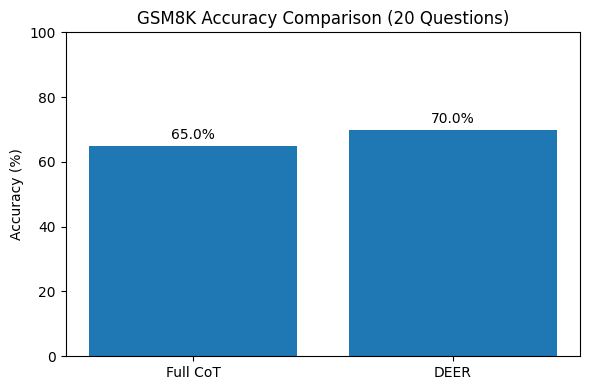

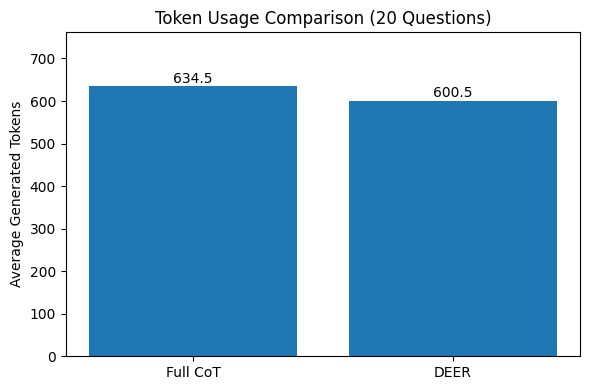

In [69]:
# -------------------------------------------------------
# Cell 44: Accuracy and average token comparison
# -------------------------------------------------------

import matplotlib.pyplot as plt

methods = ["Full CoT", "DEER"]

# Plot 1: Accuracy
accuracy = [
    comparison_df["cot_correct"].mean() * 100,
    comparison_df["deer_correct"].mean() * 100
]

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(methods, accuracy)

ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.set_title("GSM8K Accuracy Comparison (20 Questions)")

for bar, value in zip(bars, accuracy):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 2,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "accuracy_comparison.png",
    dpi=300
)
plt.show()


# Plot 2: Average generated tokens
avg_tokens = [
    comparison_df["cot_tokens"].mean(),
    comparison_df["deer_tokens"].mean()
]

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(methods, avg_tokens)

ax.set_ylabel("Average Generated Tokens")
ax.set_title("Token Usage Comparison (20 Questions)")

for bar, value in zip(bars, avg_tokens):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 8,
        f"{value:.1f}",
        ha="center"
    )

ax.set_ylim(0, max(avg_tokens) * 1.2)

plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "average_tokens_comparison.png",
    dpi=300
)
plt.show()

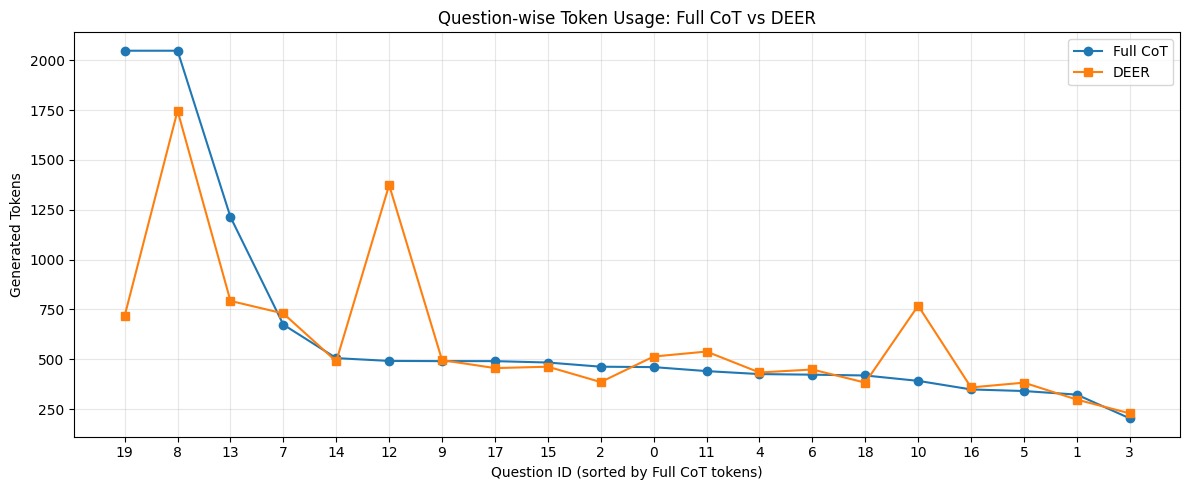

In [70]:
# -------------------------------------------------------
# Cell 45: Question-wise token savings
# -------------------------------------------------------

plot_df = comparison_df.sort_values(
    "cot_tokens",
    ascending=False
)

fig, ax = plt.subplots(figsize=(12, 5))

x = range(len(plot_df))

ax.plot(
    x,
    plot_df["cot_tokens"],
    marker="o",
    label="Full CoT"
)

ax.plot(
    x,
    plot_df["deer_tokens"],
    marker="s",
    label="DEER"
)

ax.set_xticks(list(x))
ax.set_xticklabels(
    plot_df["question_id"].astype(str)
)

ax.set_xlabel("Question ID (sorted by Full CoT tokens)")
ax.set_ylabel("Generated Tokens")
ax.set_title("Question-wise Token Usage: Full CoT vs DEER")

ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "questionwise_token_comparison.png",
    dpi=300
)
plt.show()

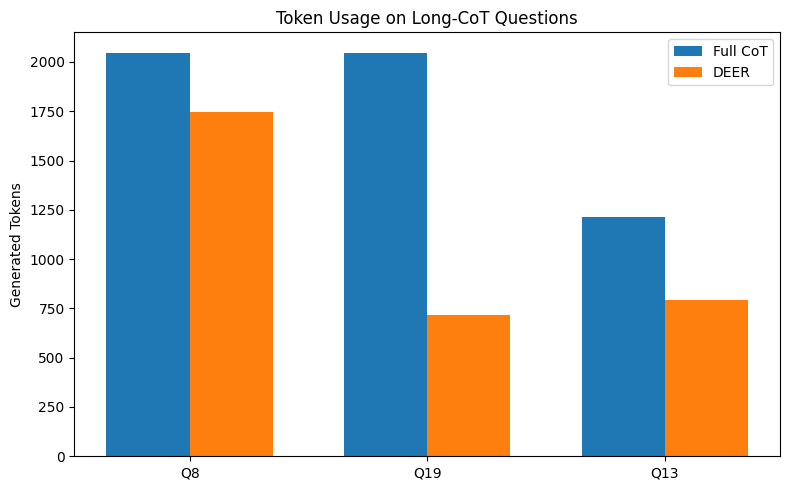

Token reduction on long-CoT subset: 38.64%


In [71]:
# -------------------------------------------------------
# Cell 46: Long-reasoning question comparison
# -------------------------------------------------------

long_df = comparison_df[
    comparison_df["cot_tokens"] >= 1000
].copy()

long_df = long_df.sort_values(
    "cot_tokens",
    ascending=False
)

x = list(range(len(long_df)))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    [i - width/2 for i in x],
    long_df["cot_tokens"],
    width,
    label="Full CoT"
)

ax.bar(
    [i + width/2 for i in x],
    long_df["deer_tokens"],
    width,
    label="DEER"
)

ax.set_xticks(x)
ax.set_xticklabels(
    ["Q" + str(q) for q in long_df["question_id"]]
)

ax.set_ylabel("Generated Tokens")
ax.set_title("Token Usage on Long-CoT Questions")

ax.legend()

plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "long_reasoning_comparison.png",
    dpi=300
)
plt.show()

if len(long_df) > 0:
    reduction = 100 * (
        1 - long_df["deer_tokens"].sum()
        / long_df["cot_tokens"].sum()
    )

    print(
        f"Token reduction on long-CoT subset: "
        f"{reduction:.2f}%"
    )